In [1]:
import numpy as np

def cliffs_delta(x, y):
    """
    Cliff's delta for two independent samples.
    δ = P(x > y) - P(x < y)
    """
    x = np.asarray(x)
    y = np.asarray(y)

    gt = 0
    lt = 0

    for xi in x:
        for yj in y:
            if xi > yj:
                gt += 1
            elif xi < yj:
                lt += 1
            # ties ignored

    return (gt - lt) / (len(x) * len(y))


def cliffs_delta_ci(x, y, n_boot=5000, ci=0.95, seed=42):
    """
    Cliff's delta with bootstrap confidence interval.

    Returns
    -------
    delta : float
        Point estimate
    (low, high) : tuple
        CI bounds
    """
    rng = np.random.default_rng(seed)

    x = np.asarray(x)
    y = np.asarray(y)

    delta_hat = cliffs_delta(x, y)

    boot = np.empty(n_boot)
    for i in range(n_boot):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)
        boot[i] = cliffs_delta(xb, yb)

    alpha = 1 - ci
    low = np.quantile(boot, alpha / 2)
    high = np.quantile(boot, 1 - alpha / 2)

    return round(delta_hat,2), round(low,2), round(high,2)


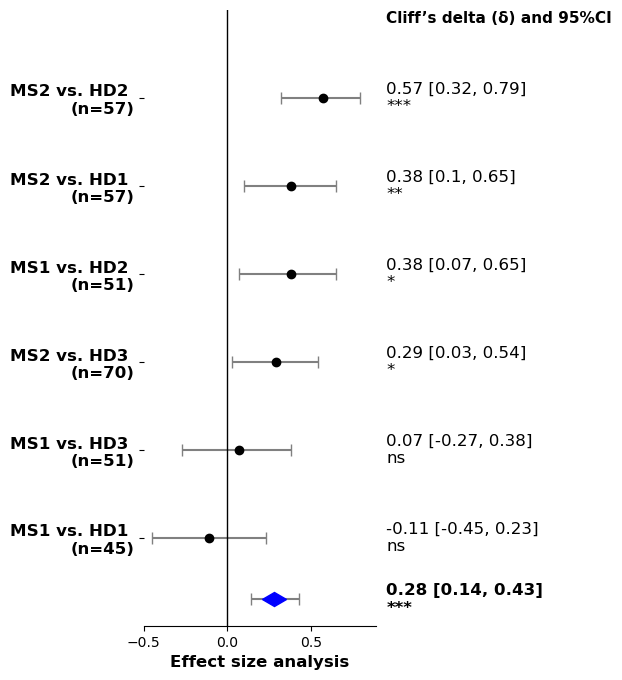

In [2]:
import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, wilcoxon

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as lines
from matplotlib.markers import MarkerStyle


def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

ms_datasets = ['ms01', 'ms03'] # 'ms02',
hd_datasets = ['hd01', 'hd02', 'microhd']

    
rslt_df = pd.DataFrame()
all_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'F:/backup_E/meta_data/subject_list/hla_balanced/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()
    
        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]
    
        hla_df2 = pd.read_csv(f'../../meta_data/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]
    
        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
    
        ms_df = pd.read_csv(f'./tables/{ms_dataset}.tsv', sep='\t')
        hd_df = pd.read_csv(f'./tables/{hd_dataset}.tsv', sep='\t')
        
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
    
        df = df.merge(hla_df, on ='subject_id')
        df = df[df['subject_id'].isin(subject_list)]
        df = df[df['HLA'] == 1]
        
        df['normalized_seqs'] = df.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment)* 10000, axis=1)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        # df = df[df['subject_id'].isin(subject_list)]
        df1 = df[df['MS_status'] == 'MS']
        df2 = df[df['MS_status'] == 'HD']
        statis, p_value = mannwhitneyu(df1['normalized_seqs'], df2['normalized_seqs'], alternative='greater')
    #         star = convert_pvalue_to_asterisks(p_value)
    
    #         df['MS_status'] = df['MS_status'].map({'HD': 1, 'MS': 0})  # binary for regression
        all_df = pd.concat([all_df, df], ignore_index=True, sort=False)
    
        nx = len(df1)
        ny = len(df2)
    
    #         df['MS_status'] = df['MS_status'].map({'HD': 1, 'MS': 0})  # binary for regression
    
        r_hat, lo, hi = cliffs_delta_ci(df1['normalized_seqs'], df2['normalized_seqs'])
        
        model = ({
            'groups': [f'{ms_dataset.upper()}_{hd_dataset.upper()}'],
            'r': [r_hat],
            'll': [lo],
            'hl': [hi],
            'n': [len(df)],
            'pval': [p_value]
    #             'p1': [round(p1, 3)]
        })
    
        model_df = pd.DataFrame(model)
        rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

# rslt_df = pd.concat([rslt_df, twins_df], ignore_index=True, sort=False)
rslt_df['groups'] = rslt_df['groups'].str.replace('_', ' vs. ')
rslt_df['groups'] = rslt_df['groups'].str.replace('0', '')
rslt_df['groups'] = rslt_df['groups'].str.replace('MS3', 'MS2')
rslt_df['groups'] = rslt_df['groups'].str.replace('MICROHD', 'HD3')

data = rslt_df.sort_values(['r']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(3,8))
# sns.set_style("whitegrid")
y_pos = np.arange(len(data))

# Plot error bars for individual groups
for i in range(len(data)):  # exclude last row (Overall)
    ax.errorbar(data['r'][i], y_pos[i],
                xerr=[[data['r'][i] - data['ll'][i]], 
                      [data['hl'][i] - data['r'][i]]],
                fmt='o', color='black', ecolor='gray', capsize=4)

all_df = all_df.drop_duplicates()
df1 = all_df[all_df['MS_status'] == 'MS']
df2 = all_df[all_df['MS_status'] == 'HD']
nx = len(df1)
ny = len(df2)

r_hat1, lo1, hi1 = cliffs_delta_ci(df1['normalized_seqs'], df2['normalized_seqs'])
stats, p_all = mannwhitneyu(df1['normalized_seqs'], df2['normalized_seqs'], alternative='greater')
star = convert_pvalue_to_asterisks(p_all)

m = MarkerStyle("d")
m._transform.rotate_deg(90)
ax.errorbar(r_hat1, -0.7, 
             xerr=[[r_hat1 - lo1], 
                   [hi1 - r_hat1]],
             color='blue', marker=m, ecolor='gray', 
             capsize=4, markersize=12)  # , marker=m, markersize=18, markerfacecolor="None"
ax.text(data.hl.max()+0.16, -0.7, f"{r_hat1} {[lo1.tolist(), hi1.tolist()]} \n{star}", va='center', fontweight='bold', fontsize=12)

labels = [f"{row['groups']} \n(n={row['n']})" for _, row in data.iterrows()]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontweight='bold', fontsize=12)

# for i, p in enumerate(data['pval']):
#     star = convert_pvalue_to_asterisks(p)
#     if p < 0.05: 
#         ax.text(data.hl.max()+0.12, y_pos[i], f"\n{star}", va='center', fontsize=12) # fontweight='bold',

i = 0
for r, ll, hl, p in zip(data['r'], data['ll'], data['hl'], data['pval']):
    star = convert_pvalue_to_asterisks(p)
    ax.text(data.hl.max()+0.16, y_pos[i], f"{round(r, 2)} [{ll}, {hl}] \n{star}", va='center', fontsize=12)
    i += 1

ax.text(data.hl.max()+0.16, len(data)-0.1, "Cliff’s delta (δ) and 95%CI", va='center', fontsize=11, fontweight='bold')

ax.axvline(0, color='black', linewidth=1)

# Axis formatting
ax.set_xlabel("Effect size analysis", fontsize=12, fontweight='bold')
ax.set_xlim(min(data['ll']) - 0.05, max(data['hl']) + 0.1)
ax.set_ylim(-1, len(data))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
# ax.set_title("Effect size analysis", fontsize=16)

# Clean layout
# plt.tight_layout()
plt.show()
plt.close()

In [4]:
ax.get_figure().savefig('C:/Users/lynda/Desktop/Figures/Fig3/myimage3.png', format='png', dpi=600, bbox_inches='tight')